# DNAscape quickstart

Prepare a real replication-timing profile, infer origin firing, predict timing, and simulate individual S phases. This notebook runs independently and needs no downloads.

**Before you start:** use Python 3.10 or newer. From the repository root, install DNAscape and JupyterLab in your active environment:

```bash
python -m pip install -e . jupyterlab
python -m jupyterlab examples
```

Choose that environment's Python kernel, open this notebook and use **Restart Kernel and Run All**. NumPy, pandas and Matplotlib are installed with DNAscape. Files go to `examples/outputs/quickstart/`.

1. [Load and select a region](#1.-Load-and-select-a-region)
2. [Map timing to initiation rate](#2.-Map-timing-to-initiation-rate)
3. [Simulate DNA replication](#3.-Simulate-DNA-replication)
4. [Export and continue](#4.-Export-and-continue)


In [1]:
from pathlib import Path
import os
import sys

# Works with Jupyter started in the repository root or in examples/.
PROJECT_DIR = next(
    (
        p
        for p in (Path.cwd(), *Path.cwd().parents)
        if (p / "dnascape" / "__init__.py").is_file()
    ),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Start Jupyter inside your DNAscape checkout.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
OUTPUT_DIR = (
    Path(
        os.environ.get("DNASCAPE_NOTEBOOK_OUTPUT", PROJECT_DIR / "examples" / "outputs")
    )
    / "quickstart"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dnascape import rload, rmap, rsim, rsave, select_profile_region, plotf

plt.rcParams.update(
    {
        "figure.figsize": (8, 3.2),
        "figure.dpi": 100,
        "axes.grid": False,
        "font.size": 10,
        "axes.prop_cycle": plt.cycler(color=["#b03412", "#3498b8", "#68615b"]),
    }
)
print(f"Outputs: {OUTPUT_DIR}")


Outputs: C:\Users\Francisco Berkemeier\Dropbox\Main Work\PostDoc\My Papers\DNAscape\github\DNAscape-devmode\examples\outputs\quickstart


## 1. Load and select a region

The bundled hESC chromosome 1 timing profile has one sample per **1 kb**. Select `[40,000, 41,000)` kb and average into 5 kb bins. The genomic interval stays fixed; changing the resolution changes the number of samples. Replace the path, chromosome or interval here to use your own data.


200 bins at 5 kb over 40000–41000 kb


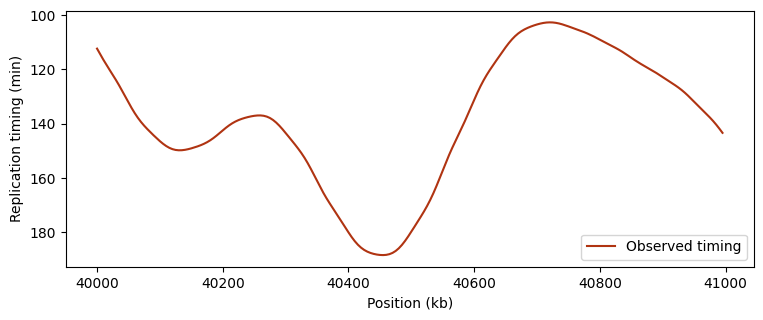

In [2]:
INPUT_PATH = PROJECT_DIR / "examples/data/example/replication_timing_hESC.csv"
REGION_KB = (40_000.0, 41_000.0)
DX_KB = 5.0
FORK_SPEED = 1.4  # kb/min
SEED = 17
REPLICATES = 48

full_timing = rload(INPUT_PATH, chromosome="chr1", data_form="space")
timing, positions_kb = select_profile_region(
    full_timing,
    raw_resolution_kb=1.0,
    interval_kb=REGION_KB,
    output_resolution_kb=DX_KB,
    resample_method="mean",
)
assert np.isfinite(timing).all() and (timing > 0).all()
print(f"{timing.size} bins at {DX_KB:g} kb over {REGION_KB[0]:g}–{REGION_KB[1]:g} kb")
plotf(
    timing,
    x_array=positions_kb,
    xtitle="Position (kb)",
    ytitle="Replication timing (min)",
    labels=["Observed timing"],
    invyQ=True,
    figsize=(8, 3.2),
)


## . Map timing to initiation rate

`rmap` selects a deterministic mapping from the supplied features and assumptions. Here the target is a spatial initiation rate, describing the potential for **origin firing** before passive replication.

**Units at the Python API boundary:** `rmap` uses initiation rate per kb per minute and fork speed in kb/min. `rsim` uses initiation rate per spatial bin per minute, so multiply the density by the bin width when passing it to a simulation. The app handles this conversion automatically.


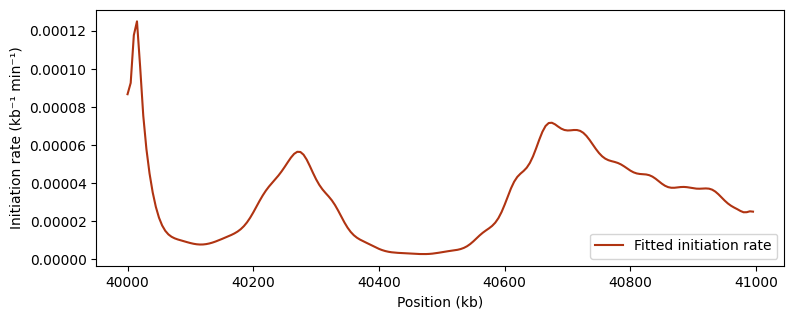

In [3]:
fit = rmap(
    source={"replication_timing": timing, "fork_speed": FORK_SPEED},
    target="initiation_rate",
    assumptions={
        "target_form": "space",
        "resolution_x": DX_KB,
        "maxiter": 12,
        "verbose": False,
    },
    return_info=True,
)
ir_x = np.asarray(fit["values"])
assert ir_x.shape == timing.shape and np.all(ir_x >= 0)
plotf(
    ir_x,
    x_array=positions_kb,
    xtitle="Position (kb)",
    ytitle="Initiation rate (kb⁻¹ min⁻¹)",
    labels=["Fitted initiation rate"],
    figsize=(8, 3.2),
)


### Check the forward prediction

Map the fitted initiation rate and constant fork speed back to timing, then calculate MSE on finite samples. A residual can reflect the assumptions, edge context, discretisation or incomplete fitting; it does not establish a particular biological cause.


Forward timing MSE: 166.455 min²


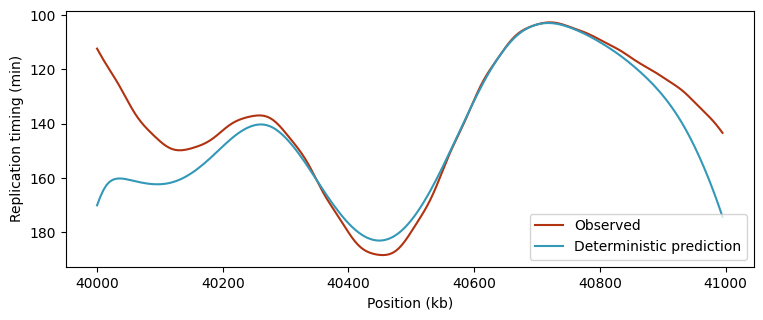

In [4]:
mapped_timing = rmap(
    source={"initiation_rate": ir_x, "fork_speed": FORK_SPEED},
    target="replication_timing",
    assumptions={"resolution_x": DX_KB, "verbose": False},
)
valid = np.isfinite(timing) & np.isfinite(mapped_timing)
mapping_mse = np.mean((mapped_timing[valid] - timing[valid]) ** 2)
print(f"Forward timing MSE: {mapping_mse:.3f} min²")
plotf(
    timing,
    mapped_timing,
    x_array=positions_kb,
    labels=["Observed", "Deterministic prediction"],
    invyQ=True,
    xtitle="Position (kb)",
    ytitle="Replication timing (min)",
    figsize=(8, 3.2),
)


### Derive fork directionality

Directionality is signed: positive values indicate predominantly right-moving forks and negative values indicate left-moving forks. This example uses the predicted timing, so both derived profiles describe the same fitted model.


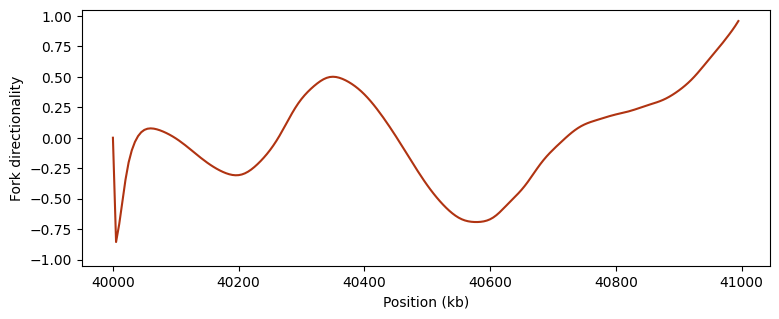

In [5]:
rfd = rmap(
    source={"replication_timing": mapped_timing, "fork_speed": FORK_SPEED},
    target="fork_directionality",
    assumptions={"resolution_x": DX_KB, "verbose": False},
)
plotf(
    rfd,
    x_array=positions_kb,
    xtitle="Position (kb)",
    ytitle="Fork directionality",
    limsy=(-1.05, 1.05),
    figsize=(8, 3.2),
)


## 3. Simulate DNA replication

`rsim` generates stochastic S phases from the kinetic inputs. A fixed seed makes the example reproducible. `time_statsQ=True` also records time courses and completed replicon lengths. Increase `REPLICATES` for a more stable population mean.


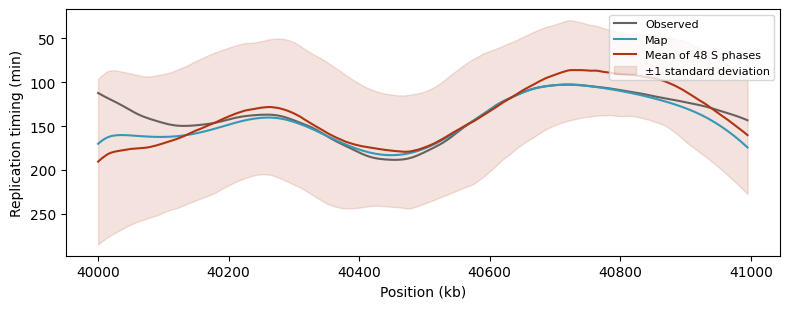

In [6]:
simulation = rsim(
    source={"initiation_rate": ir_x * DX_KB, "fork_speed": FORK_SPEED},
    assumptions={
        "resolution_x": DX_KB,
        "sim_number": REPLICATES,
        "seed": SEED,
        "time_statsQ": True,
        "time_grid": np.arange(0.0, 1201.0, 5.0),
        "max_rep_time": 1200.0,
        "verbose": False,
    },
)
replicate_timing = np.asarray(simulation["rep_times_per_sim"])
mean_timing = np.asarray(simulation["replication_timing"])
assert np.isfinite(replicate_timing).all(), "Increase max_rep_time for this model."
std_timing = replicate_timing.std(axis=0)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(positions_kb, timing, label="Observed", color="#68615b")
ax.plot(positions_kb, mapped_timing, label="Map", color="#3498b8")
ax.plot(positions_kb, mean_timing, label=f"Mean of {REPLICATES} S phases")
ax.fill_between(
    positions_kb,
    mean_timing - std_timing,
    mean_timing + std_timing,
    color="#b03412",
    alpha=0.14,
    label="±1 standard deviation",
)
ax.set(xlabel="Position (kb)", ylabel="Replication timing (min)")
ax.invert_yaxis()
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()


### Inspect progression and origin firing

The time grid records when outputs are sampled. `origin_firing` is the mean number of **actual initiations per time interval**, distinct from the potential initiation rate supplied to the model.


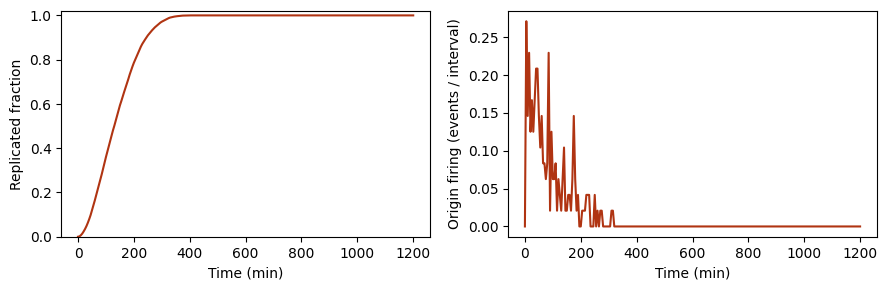

,Completion time (min),Fired origins
count,48.00,48.00
mean,267.76,4.06
std,55.59,1.06
min,166.03,2.00
25%,228.70,3.00
50%,261.59,4.00
75%,306.15,5.00
max,403.03,7.00


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(simulation["time_grid"], simulation["replicated_fraction"])
axes[0].set(xlabel="Time (min)", ylabel="Replicated fraction", ylim=(0, 1.02))
axes[1].plot(simulation["time_grid"], simulation["origin_firing"])
axes[1].set(xlabel="Time (min)", ylabel="Origin firing (events / interval)")
fig.tight_layout()
plt.show()
pd.DataFrame(
    {
        "Completion time (min)": simulation["completion_time"],
        "Fired origins": simulation["num_origins"],
    }
).describe().round(2)


## 4. Export and continue

Save both the initiation-rate density and the per-bin simulation input with unambiguous labels. The NPZ keeps coordinates, units and simulation settings together.


In [8]:
rsave(
    pd.DataFrame(
        {
            "position_kb": positions_kb,
            "initiation_rate_per_kb_min": ir_x,
            "initiation_rate_per_bin_min": ir_x * DX_KB,
        }
    ),
    OUTPUT_DIR / "initiation_rate_x.tsv",
)
np.savez_compressed(
    OUTPUT_DIR / "quickstart_results.npz",
    positions_kb=positions_kb,
    resolution_kb=DX_KB,
    seed=SEED,
    initiation_rate_per_kb_min=ir_x,
    fork_speed_kb_min=FORK_SPEED,
    timing_observed_min=timing,
    timing_mapped_min=mapped_timing,
    timing_simulated_min=mean_timing,
    timing_std_min=std_timing,
)
print("Saved initiation_rate_x.tsv and quickstart_results.npz")


Saved initiation_rate_x.tsv and quickstart_results.npz


Continue with [data management](1-data_management.ipynb), the [mapping atlas](2-mapping.ipynb), [simulation](3-simulation.ipynb), [worked studies](4-neat_examples.ipynb), or [plotting](5-plotting.ipynb). The [documentation](https://dnascape.readthedocs.io/en/latest/) provides further API details.

Timing alone does not uniquely identify both initiation rate and fork speed. Compare constrained hypotheses and use independent measurements when interpreting fitted kinetics.
